# Current against length, $I \propto L^e$: same-spot gain ratios of several 4-fish recordings

Each recording has its own notebook `EOD_gain_vs_length_4fish_<recording>.ipynb` (same script, same rules): isolated EODs (every other
fish ≥ 210 px away) in frames where all four masks pass the QC; two fish compared only **at the same spot** (centroids ≤ 15 px,
headings ≤ 15°), and only when both EODs are clearly their fish's by shape (my model, BEM conductivities, sink at the tail tip, sign
fixed; shape distance ≤ 0.3, every other fish ≥ 0.3 worse). At the same spot the electrodes and any location-dependent error are the
same, so the gain ratio of the two EODs is $a_f/a_g = (L_f/L_g)^e$ × the two fish's individual difference.

Within a recording the amplifier gain is common; across recordings only ratios within a recording are used, so a different gain per
recording does not matter. Two estimates of e:

- **slope through the origin** of $\log(a_f/a_g)$ on $\log(L_f/L_g)$ over all matches (assumes the fish differ only by length; the
  bootstrap resamples matches within each recording and pair of fish);
- **fish effects**: per recording, $\alpha_f$ fitted to its matches (mean 0; fish not linked to the others by matches are left out),
  then $\alpha_{rf} = c_r + e\,\log L_{rf}$ over all fish of all recordings (one intercept per recording). Its interval counts each
  fish as one observation, so individual differences between fish are in it.

In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
%matplotlib inline

RECS = ['2024-02-20T21_16_26', '2024-02-20T18_16_24', '2024-10-23T15_18_28']
GROUP = {'2024-02-20T21_16_26': '2024-02-20', '2024-02-20T18_16_24': '2024-02-20', '2024-10-23T15_18_28': '2024-10-23'}   # same fish within a group
RCOL = {'2024-02-20T21_16_26': '#C8361E', '2024-02-20T18_16_24': '#E8A317', '2024-10-23T15_18_28': '#1F5FBF'}
OUT = 'results/eod_gain_4fish'
FISH = (0, 1, 2, 3); LET = 'ABCD'
L, MK = {}, []
for r in RECS:
    j = json.load(open(f'{OUT}/{r}/fish_lengths_4fish.json'))
    L[r] = np.array([j['fish'][str(f)]['L_px'] / j['px_per_cm'] for f in FISH])
    m = pd.read_csv(f'{OUT}/{r}/same_spot_matches.csv'); m['rec'] = r; MK.append(m)
MK = pd.concat(MK, ignore_index=True)
display(pd.DataFrame(L, index=[f'fish {c}' for c in LET]).round(2).rename_axis('L (cm)'))
display(MK.assign(pair=MK.fish_a.map(dict(enumerate(LET))) + '/' + MK.fish_b.map(dict(enumerate(LET))))
        .pivot_table(index='rec', columns='pair', values='log_ratio', aggfunc='size', fill_value=0).assign(total=lambda t: t.sum(1)))

,2024-02-20T21_16_26,2024-02-20T18_16_24,2024-10-23T15_18_28
L (cm),,,
fish A,14.74,14.40,18.08
fish B,12.95,12.85,12.90
fish C,9.36,9.17,12.90
fish D,8.18,8.26,8.62


pair,A/B,A/C,A/D,B/C,B/D,C/D,total
rec,,,,,,,
2024-02-20T18_16_24,6,2,1,1,4,0,14
2024-02-20T21_16_26,20,6,0,0,4,1,31
2024-10-23T15_18_28,0,0,0,315,0,0,315


## Fit of e

In [2]:
def slope0(mk): return (mk.log_ratio * mk.log_L_ratio).sum() / (mk.log_L_ratio ** 2).sum()

def fish_effects(mk):
    '''alpha (4,) for one recording, mean 0 over the fish linked by matches to the best-linked fish; NaN for the others.'''
    linked = {int(mk.fish_a.value_counts().add(mk.fish_b.value_counts(), fill_value=0).idxmax())}
    while True:
        new = linked | set(mk.fish_b[mk.fish_a.isin(linked)]) | set(mk.fish_a[mk.fish_b.isin(linked)])
        if new == linked: break
        linked = new
    fl = sorted(linked); m = mk[mk.fish_a.isin(fl) & mk.fish_b.isin(fl)]
    X = np.zeros((len(m) + 1, len(fl))); idx = {f: j for j, f in enumerate(fl)}
    X[np.arange(len(m)), m.fish_a.map(idx)] = 1; X[np.arange(len(m)), m.fish_b.map(idx)] = -1; X[-1] = 1
    a = np.full(4, np.nan); a[fl] = np.linalg.lstsq(X, np.r_[m.log_ratio, 0], rcond=None)[0]
    return a

def effects_fit(mk):
    '''e from alpha_rf = c_r + e log L_rf: OLS with one intercept per recording. Returns e, SE, dof, table of alphas.'''
    rows = []
    for r, g in mk.groupby('rec'):
        a = fish_effects(g)
        rows += [dict(rec=r, fish=f, alpha=a[f], logL=np.log(L[r][f])) for f in FISH if np.isfinite(a[f])]
    t = pd.DataFrame(rows)
    X = np.c_[t.logL, pd.get_dummies(t.rec).to_numpy(float)]
    b, *_ = np.linalg.lstsq(X, t.alpha.to_numpy(), rcond=None)
    dof = len(t) - X.shape[1]
    res = t.alpha.to_numpy() - X @ b
    se = np.sqrt(res @ res / dof * np.linalg.inv(X.T @ X)[0, 0]) if dof > 0 else np.nan
    t['alpha_centered'] = t.alpha - t.groupby('rec').alpha.transform('mean')
    t['logL_centered'] = t.logL - t.groupby('rec').logL.transform('mean')
    return b[0], se, dof, t

groups = [g for _, g in MK.groupby(['rec', 'fish_a', 'fish_b'])]
rng = np.random.default_rng(3); b0, bf = [], []
for _ in range(2000):
    mk = pd.concat([g.sample(len(g), replace=True, random_state=rng) for g in groups])
    b0.append(slope0(mk)); bf.append(effects_fit(mk)[0])

def summary(mk, label):
    e_f, se, dof, _ = effects_fit(mk)
    return {'what': label, 'matches': len(mk), 'e, slope through origin': slope0(mk), 'e, fish effects': e_f, 'SE': se, 'dof': dof,
            'fish-effects 95% (t)': (e_f - stats.t.ppf(0.975, dof) * se, e_f + stats.t.ppf(0.975, dof) * se) if dof > 0 else (np.nan, np.nan)}
rows = [summary(MK, 'all recordings')]
rows[0]['slope bootstrap 95%'] = tuple(np.percentile(b0, [2.5, 97.5])); rows[0]['fish-effects bootstrap 95%'] = tuple(np.percentile(bf, [2.5, 97.5]))
rows += [summary(MK[MK.rec != r], f'without {r}') for r in RECS]
rows += [summary(MK[MK.rec.isin([r for r in RECS if GROUP[r] == g])], f'only group {g}') for g in sorted(set(GROUP.values()))]
rows += [summary(MK[MK.rec == r], f'only {r}') for r in RECS]
E = pd.DataFrame(rows).set_index('what')
E.to_csv(f'{OUT}/combined_fit_e.csv')
with pd.option_context('display.float_format', '{:.3f}'.format, 'display.max_colwidth', 40): display(E)
e_all, se_all, dof_all, T = effects_fit(MK)
T.to_csv(f'{OUT}/combined_fish_effects.csv', index=False)

# one point per individual: the recordings of a group have the same four fish (same lengths), so their centred effects are averaged
T['group'] = T.rec.map(GROUP)
I = T.groupby(['group', 'fish']).agg(alpha=('alpha_centered', 'mean'), logL=('logL', 'mean'), n_rec=('rec', 'size')).reset_index()
I['alpha'] -= I.groupby('group').alpha.transform('mean'); I['logL_c'] = I.logL - I.groupby('group').logL.transform('mean')
Xi = np.c_[I.logL, pd.get_dummies(I.group).to_numpy(float)]
bi, *_ = np.linalg.lstsq(Xi, I.alpha.to_numpy(), rcond=None); dof_i = len(I) - Xi.shape[1]
res_i = I.alpha.to_numpy() - Xi @ bi; se_i = np.sqrt(res_i @ res_i / dof_i * np.linalg.inv(Xi.T @ Xi)[0, 0])
print(f'one point per individual fish ({len(I)} fish, {I.group.nunique()} groups): e = {bi[0]:.3f}, SE {se_i:.3f}, '
      f'95% {bi[0] - stats.t.ppf(0.975, dof_i) * se_i:.2f} to {bi[0] + stats.t.ppf(0.975, dof_i) * se_i:.2f} (dof {dof_i})')
pd.DataFrame({'e': [bi[0]], 'SE': [se_i], 'dof': [dof_i], 'n fish': [len(I)]}).to_csv(f'{OUT}/combined_fit_e_per_individual.csv', index=False)
display(I.assign(fish=I.fish.map(dict(enumerate(LET))), L_cm=np.exp(I.logL), rel_gain=np.exp(I.alpha)).round(3))
display(T.assign(fish=T.fish.map(dict(enumerate(LET))), L_cm=np.exp(T.logL), rel_gain=np.exp(T.alpha)).round(3))

,matches,"e, slope through origin","e, fish effects",SE,dof,fish-effects 95% (t),slope bootstrap 95%,fish-effects bootstrap 95%
what,,,,,,,,
all recordings,360,0.313,0.217,0.286,6,"(-0.4835390546367384, 0.917807824399...","(0.1191184370097942, 0.5184557061060...","(0.04417029538347612, 0.402648055208..."
without 2024-02-20T21_16_26,329,0.246,0.227,0.554,3,"(-1.5353289356103774, 1.989246363764...",NaN,NaN
without 2024-02-20T18_16_24,346,0.360,0.208,0.175,3,"(-0.3479386093566498, 0.763820140370...",NaN,NaN
without 2024-10-23T15_18_28,45,0.313,0.217,0.314,5,"(-0.589157208794154, 1.0234279298811...",NaN,NaN
only group 2024-02-20,45,0.313,0.217,0.314,5,"(-0.589157208794154, 1.0234279298811...",NaN,NaN
only group 2024-10-23,315,-61.860,-61.860,NaN,0,"(nan, nan)",NaN,NaN
only 2024-02-20T21_16_26,31,0.360,0.208,0.214,2,"(-0.7119204215912232, 1.127805729047...",NaN,NaN
only 2024-02-20T18_16_24,14,0.246,0.227,0.678,2,"(-2.690923493367013, 3.144844959104344)",NaN,NaN
only 2024-10-23T15_18_28,315,-61.860,-61.860,NaN,0,"(nan, nan)",NaN,NaN


one point per individual fish (6 fish, 2 groups): e = 0.225, SE 0.349, 95% -0.88 to 1.33 (dof 3)


,group,fish,alpha,logL,n_rec,logL_c,L_cm,rel_gain
0,2024-02-20,A,0.157,2.679,2,0.287,14.572,1.170
1,2024-02-20,B,-0.128,2.557,2,0.165,12.901,0.880
2,2024-02-20,C,0.143,2.226,2,-0.166,9.266,1.154
3,2024-02-20,D,-0.172,2.107,2,-0.286,8.220,0.842
4,2024-10-23,B,0.004,2.557,1,-0.000,12.900,1.004
5,2024-10-23,C,-0.004,2.557,1,0.000,12.902,0.996


,rec,fish,alpha,logL,alpha_centered,logL_centered,group,L_cm,rel_gain
0,2024-02-20T18_16_24,A,0.179,2.667,0.179,0.280,2024-02-20,14.404,1.196
1,2024-02-20T18_16_24,B,-0.179,2.553,-0.179,0.166,2024-02-20,12.851,0.836
2,2024-02-20T18_16_24,C,0.266,2.216,0.266,-0.171,2024-02-20,9.172,1.305
3,2024-02-20T18_16_24,D,-0.266,2.111,-0.266,-0.276,2024-02-20,8.259,0.767
4,2024-02-20T21_16_26,A,0.135,2.691,0.135,0.293,2024-02-20,14.743,1.144
5,2024-02-20T21_16_26,B,-0.076,2.561,-0.076,0.164,2024-02-20,12.951,0.927
6,2024-02-20T21_16_26,C,0.019,2.237,0.019,-0.161,2024-02-20,9.361,1.020
7,2024-02-20T21_16_26,D,-0.078,2.102,-0.078,-0.296,2024-02-20,8.181,0.925
8,2024-10-23T15_18_28,B,0.004,2.557,0.004,-0.000,2024-10-23,12.900,1.004
9,2024-10-23T15_18_28,C,-0.004,2.557,-0.004,0.000,2024-10-23,12.902,0.996


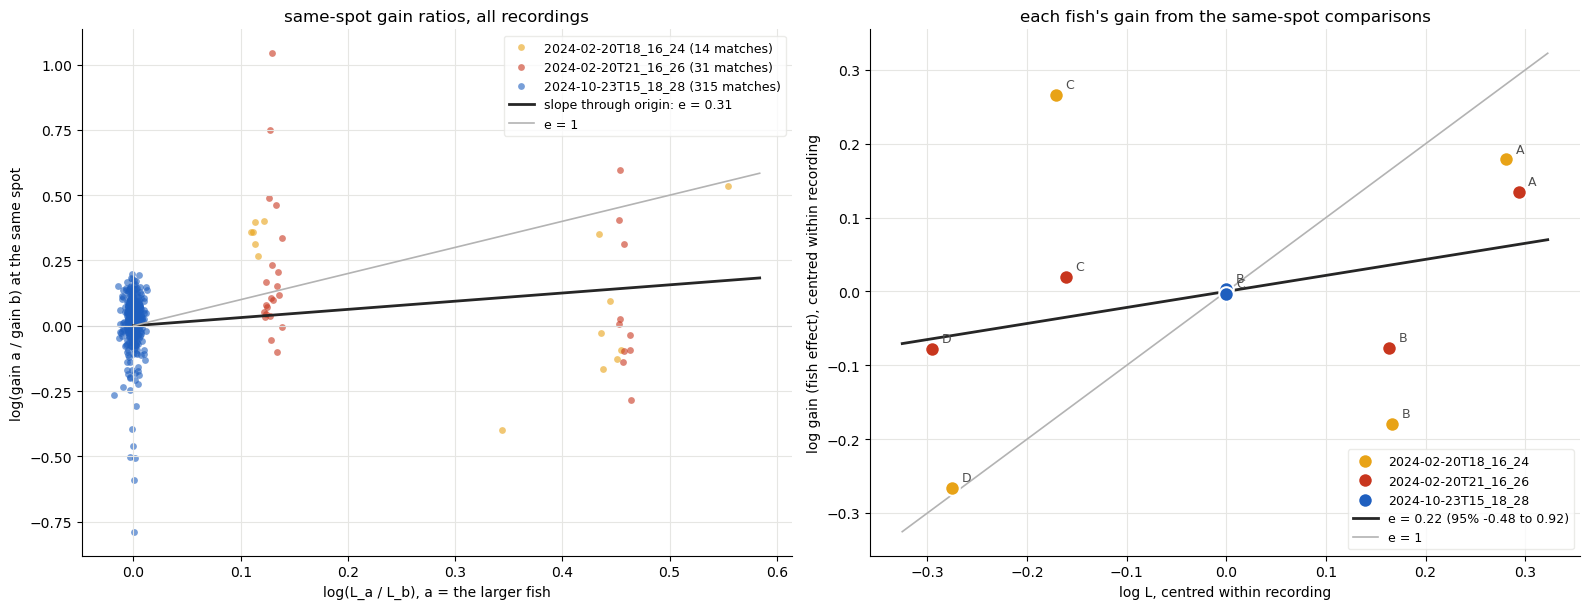

In [3]:
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False})
fig, axs = plt.subplots(1, 2, figsize=(16, 6.2))
ax = axs[0]
for r, g in MK.groupby('rec'):
    ax.scatter(g.log_L_ratio + rng.normal(0, 0.005, len(g)), g.log_ratio, s=24, color=RCOL[r], alpha=0.6, lw=0, label=f'{r} ({len(g)} matches)')
xx = np.linspace(0, MK.log_L_ratio.max() * 1.05, 20)
ax.plot(xx, slope0(MK) * xx, color='0.15', lw=2, label=f'slope through origin: e = {slope0(MK):.2f}')
ax.plot(xx, xx, color='0.7', lw=1.2, label='e = 1')
ax.axhline(0, color='0.85', lw=0.8)
ax.set(xlabel='log(L_a / L_b), a = the larger fish', ylabel='log(gain a / gain b) at the same spot', title='same-spot gain ratios, all recordings')
ax.legend(fontsize=9, frameon=True, facecolor='white', edgecolor='#e6e6e3'); ax.grid(True, color='#e6e6e3')
ax = axs[1]
for r, g in T.groupby('rec'):
    ax.scatter(g.logL_centered, g.alpha_centered, s=110, color=RCOL[r], edgecolor='white', lw=1.5, zorder=3, label=r)
    for x_, y_, f in zip(g.logL_centered, g.alpha_centered, g.fish): ax.annotate(LET[f], (x_, y_), xytext=(7, 5), textcoords='offset points', fontsize=9, color='0.3')
xx = np.linspace(T.logL_centered.min() * 1.1, T.logL_centered.max() * 1.1, 20)
lo, hi = E.loc['all recordings', 'fish-effects 95% (t)']
ax.plot(xx, e_all * xx, color='0.15', lw=2, label=f'e = {e_all:.2f} (95% {lo:.2f} to {hi:.2f})')
ax.plot(xx, xx, color='0.7', lw=1.2, label='e = 1')
ax.set(xlabel='log L, centred within recording', ylabel='log gain (fish effect), centred within recording',
       title='each fish\'s gain from the same-spot comparisons')
ax.legend(fontsize=9, frameon=True, facecolor='white', edgecolor='#e6e6e3'); ax.grid(True, color='#e6e6e3')
plt.tight_layout(); fig.savefig(f'{OUT}/combined_e_from_same_spot.png', dpi=120); plt.show()